In [79]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

cols = ['product_group_name', 'price', 'age']

path = '../data/processed/merged_cleaned_2019.csv'

df = pd.read_csv(path,
    usecols=cols
)
 

In [80]:
print(df['age'].describe())
  

count    1.639693e+07
mean     3.632804e+01
std      1.295963e+01
min      1.600000e+01
25%      2.600000e+01
50%      3.200000e+01
75%      4.800000e+01
max      9.900000e+01
Name: age, dtype: float64


In [81]:
age_bins = [0, 24, 34, 44, 54, 64, 120]

age_labels = ['<25', '25-34', '35-44', '45-54', '55-64', '65+']

df['age_band'] = pd.cut(df['age'],bins=age_bins,labels=age_labels)

df['age_band'].value_counts().sort_index()




 

age_band
<25      3172037
25-34    6108243
35-44    2112389
45-54    3206561
55-64    1493048
65+       304652
Name: count, dtype: int64

In [82]:
age_band_summary = df.groupby('age_band', observed=False)['price'].agg(purchases='size', revenue='sum')



age_band_summary['revenue_share'] = age_band_summary['revenue'] / age_band_summary['revenue'].sum()

age_band_summary['avg_price'] = age_band_summary['revenue'] / age_band_summary['purchases']

age_band_summary.round(4)

 

,purchases,revenue,revenue_share,avg_price
age_band,,,,
<25,3172037,82028.8038,0.1800,0.0259
25-34,6108243,170721.5048,0.3747,0.0279
35-44,2112389,57960.3217,0.1272,0.0274
45-54,3206561,91096.8068,0.1999,0.0284
55-64,1493048,44477.1031,0.0976,0.0298
65+,304652,9320.3378,0.0205,0.0306


In [83]:
 
age_category_summary = df.pivot_table(
    index='age_band', columns='product_group_name',
    values='price', aggfunc='sum', observed=False
)
age_category_summary.round(0)

product_group_name,Accessories,Bags,Cosmetic,Furniture,Garment Full body,Garment Lower body,Garment Upper body,Garment and Shoe care,Interior textile,Items,Nightwear,Shoes,Socks & Tights,Swimwear,Underwear,Underwear/nightwear,Unknown
age_band,,,,,,,,,,,,,,,,,
<25,2878.0,32.0,0.0,0.0,10910.0,20650.0,30326.0,0.0,0.0,5.0,700.0,2324.0,620.0,7715.0,5775.0,0.0,92.0
25-34,4993.0,35.0,1.0,1.0,26343.0,43146.0,62822.0,0.0,0.0,7.0,1633.0,6581.0,1508.0,12876.0,10558.0,4.0,213.0
35-44,1548.0,10.0,1.0,1.0,8959.0,15746.0,21656.0,0.0,0.0,2.0,635.0,2268.0,559.0,3160.0,3333.0,2.0,80.0
45-54,2167.0,18.0,1.0,1.0,13515.0,25082.0,35733.0,0.0,0.0,4.0,934.0,2645.0,777.0,5501.0,4602.0,0.0,117.0
55-64,1042.0,7.0,0.0,0.0,6750.0,11603.0,18913.0,0.0,0.0,2.0,393.0,1492.0,325.0,2135.0,1765.0,1.0,48.0
65+,243.0,1.0,0.0,0.0,1315.0,2397.0,4454.0,0.0,0.0,1.0,91.0,319.0,48.0,233.0,213.0,0.0,5.0


In [84]:
age_band_share =age_category_summary.div(age_category_summary.sum(axis=1), axis=0) 


overall_share = age_category_summary.sum() / age_category_summary.sum().sum() 

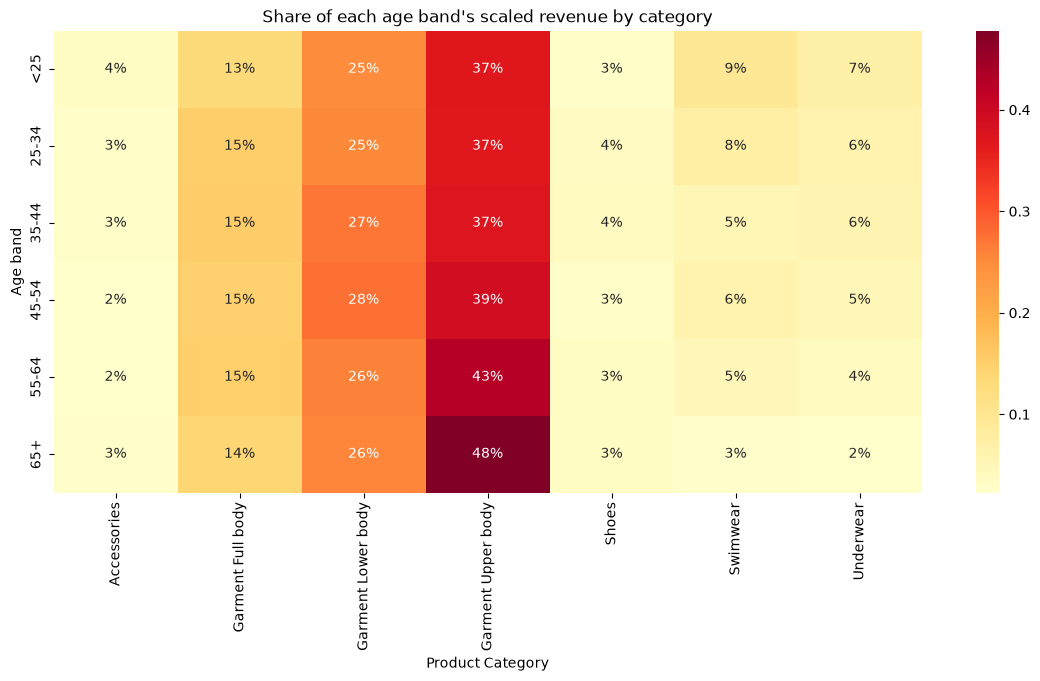

In [85]:
     

major_categories = overall_share[overall_share >= 0.01].index    

plt.figure(figsize=(14, 6))

sns.heatmap(
  age_band_share[major_categories], 
  cmap='YlOrRd', 
  annot=True, 
  fmt='.0%')

plt.title("Share of each age band's scaled revenue by category")

plt.xlabel('Product Category')
plt.ylabel('Age band')
plt.show()

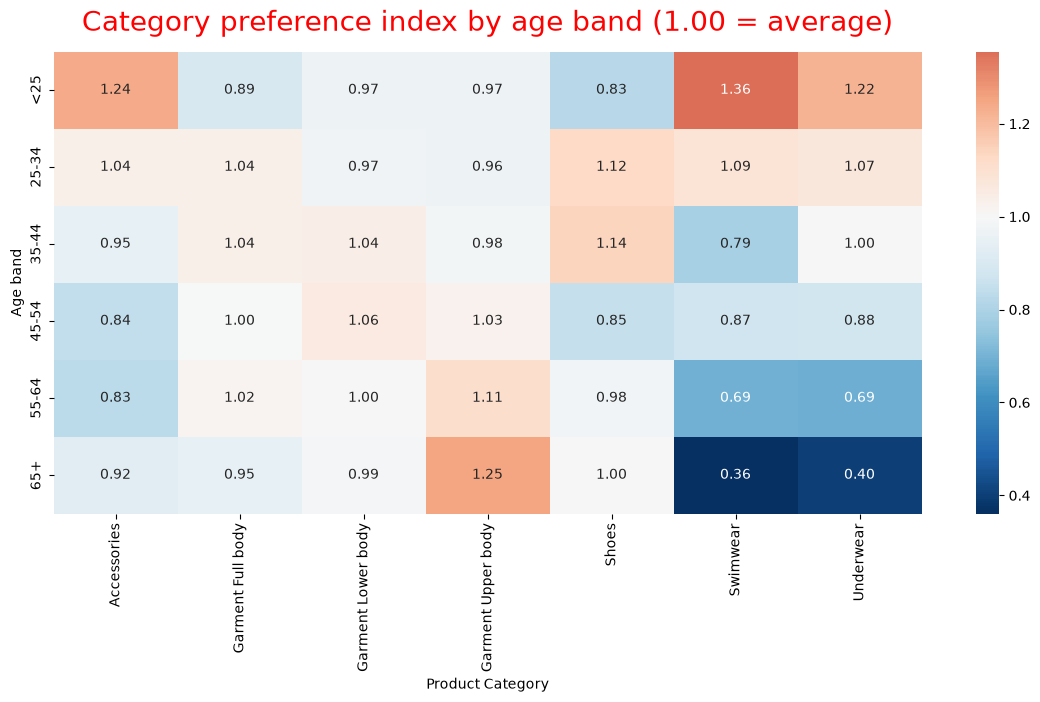

In [86]:
preference_index = age_band_share.div(overall_share, axis=1)

plt.figure(figsize=(14, 6))

sns.heatmap(
  preference_index[major_categories],
  cmap='RdBu_r', 
  center=1, 
  annot=True,
  fmt = '.2f'
 
)

plt.title('Category preference index by age band (1.00 = average)',fontsize=20,pad=15,color='red')

plt.xlabel('Product Category')
plt.ylabel('Age band')

plt.savefig('../reports/age_preference_index.png', dpi=150, bbox_inches='tight')


plt.show()

In [87]:
summary = pd.DataFrame({
    'top_category': age_band_share.idxmax(axis=1),
    'top_share': age_band_share.max(axis=1).round(3),
    'most_over_indexed': preference_index[major_categories].idxmax(axis=1),
    'index_value': preference_index[major_categories].max(axis=1).round(2),
})
summary

,top_category,top_share,most_over_indexed,index_value
age_band,,,,
<25,Garment Upper body,0.370,Swimwear,1.36
25-34,Garment Upper body,0.368,Shoes,1.12
35-44,Garment Upper body,0.374,Shoes,1.14
45-54,Garment Upper body,0.392,Garment Lower body,1.06
55-64,Garment Upper body,0.425,Garment Upper body,1.11
65+,Garment Upper body,0.478,Garment Upper body,1.25


## Findings

Garment Upper body is the top category in every age band, which fits it being the largest category overall. Its share of scaled revenue rises with age, from about 37% under 45 to 47.8% for 65+. The 65+ puts a 25% bigger share of its spending into it than customers overall with  a preference index of 1.25.

Customers under 25 over-index on Swimwear, with an index of 1.36, the strongest in the table. The other bands lean only slightly, with indexes between 1.06 and 1.14.

Age belongs to the customer and each row is a purchase, so these results describe purchases and not people. They come from one year of 